# 02 · Stiffness and choosing the integrator

Semi-discrete systems are stiff: their fastest modes are grid artefacts with rates −4κ/Δx², far faster than
anything in the solution. This notebook makes stiffness quantitative - spectra, stiffness ratios, the stability
regions of the integrators and the step each one can take - and then compares the integrators on the same
problem: explicit Runge-Kutta pinned at its stability limit, the adaptive solver wasting its steps, BDF and the
trapezoidal rule stepping at the solution's pace, and the difference between A-stability and L-stability that
shows up as ringing. It ends with a cost model that says when implicit methods win.

**What you will learn**
- compute the spectrum and stiffness ratio of a semi-discrete system
- find the stability limit of an explicit method from its stability function
- distinguish A-stable from L-stable methods and recognise ringing
- estimate explicit versus implicit cost

**Before you start:** notebook 00; the ODE notebooks of engnumeric help  ·  **Time:** about 75 min

In [1]:
try:                      # on Google Colab (or anywhere engmolines is missing): install it from GitHub
    import engmolines
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/engmolines"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from engmolines import grids, boundary as bc, operators as op, integrators as ti, stencils as st, stiffness, analysis
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## Spectra and stiffness ratios

In [2]:
rows = []
for n in (10, 20, 40, 80):
    g = grids.uniform(0, 1, n)
    f = lambda t, u, g=g: op.diffusion(u, g, 1.0, bc.Dirichlet(0.0), bc.Dirichlet(0.0), t)
    lam = stiffness.spectrum(f, np.zeros(n + 1), band=(1, 1)); lam = lam[np.abs(lam) > 1e-9]
    rows.append((n, lam[0].real, -4 / g.dx**2, stiffness.stiffness_ratio(lam), stiffness.explicit_step_limit(lam, "rk4"), stiffness.explicit_step_limit(lam, "euler")))
print(pd.DataFrame(rows, columns=["n", "lambda_min", "-4/dx^2", "stiffness ratio", "RK4 step limit", "Euler step limit"]).to_string(index=False, float_format="%.4g"))

 n  lambda_min   -4/dx^2  stiffness ratio  RK4 step limit  Euler step limit
10      -390.2      -400            39.86        0.007138          0.005125
20       -1590     -1600            161.4        0.001752          0.001258
40       -6390     -6400            647.8       0.0004359          0.000313
80  -2.559e+04 -2.56e+04             2593       0.0001088         7.816e-05


Refining the grid by two multiplies the extreme eigenvalue by four and the stiffness ratio by four, and divides
the explicit step by four: the explicit cost of the heat equation grows like n³ in 1-D (n points × n² steps) -
and like n⁴ in 2-D. The theoretical value −4/Δx² is the exact bound; the largest grid mode comes within a
fraction of a percent of it.

## Stability regions

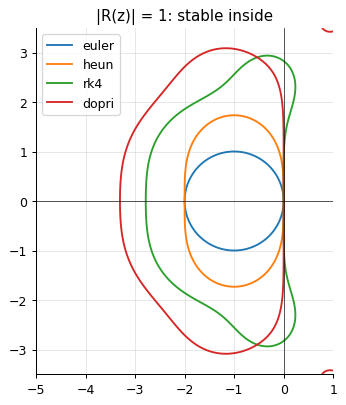

A-stable (|R| <= 1 on the whole imaginary axis): trapezoidal True ; BDF2 True
|R(-1000)|: trapezoidal 0.996 (not L-stable), backward Euler 0.001, BDF2 0.022


In [3]:
X, Y = np.meshgrid(np.linspace(-5, 1, 300), np.linspace(-3.5, 3.5, 300)); Z = X + 1j * Y
fig, ax = plt.subplots(figsize=(6, 5))
for i, m in enumerate(("euler", "heun", "rk4", "dopri")):
    ax.contour(X, Y, np.abs(stiffness.stability_function(m, Z)), [1.0], colors=f"C{i}"); ax.plot([], [], color=f"C{i}", label=m)
ax.axhline(0, color="k", lw=0.5); ax.axvline(0, color="k", lw=0.5); ax.set_aspect("equal"); ax.legend(); ax.set_title("|R(z)| = 1: stable inside"); plt.show()
th = np.linspace(-200, 200, 801)
print("A-stable (|R| <= 1 on the whole imaginary axis): trapezoidal", np.max(np.abs(stiffness.stability_function("trapezoidal", 1j * th))) <= 1 + 1e-12, "; BDF2", np.max(np.abs(stiffness.stability_function("bdf2", 1j * th))) <= 1 + 1e-12)
print(f"|R(-1000)|: trapezoidal {abs(stiffness.stability_function('trapezoidal', -1000.0)):.3f} (not L-stable), backward Euler {abs(stiffness.stability_function('backward_euler', -1000.0)):.3f}, BDF2 {abs(stiffness.stability_function('bdf2', -1000.0)):.3f}")

On y′ = λy a method multiplies the solution by R(hλ) per step; it is stable when |R| ≤ 1. The explicit methods'
regions are bounded - RK4 reaches −2.79 on the negative real axis, Euler only −2 - so the stiffest mode sets the
step. The trapezoidal rule and BDF2 are A-stable (the whole left half-plane), but only BDF2 (and backward
Euler) are L-stable: R → 0 as hλ → −∞, so the fastest modes are damped in one step, while the trapezoidal rule
multiplies them by nearly −1 and they ring.

## The integrators side by side

In [4]:
g = grids.uniform(0, 1, 40)
f = lambda t, u: op.diffusion(u, g, 1.0, bc.Dirichlet(0.0), bc.Dirichlet(0.0), t)   # noqa: E731
u0 = np.sin(np.pi * g.x)
A = st.diff_operator(g.x, 2, 2).to_dense(); A[0, :] = A[-1, :] = 0.0
ref = ti.exponential(A, u0, (0, 0.1)).y[-1]
lam = stiffness.spectrum(f, u0, band=(1, 1)); lam = lam[np.abs(lam) > 1e-9]
h_rk4 = stiffness.explicit_step_limit(lam, "rk4")
runs = {"RK4 at 0.95 of its limit": ti.explicit_rk(f, u0, (0, 0.1), 0.95 * h_rk4),
        "RK4 at 1.05 of its limit": ti.explicit_rk(f, u0, (0, 0.1), 1.05 * h_rk4),
        "Dormand-Prince rtol 1e-6": ti.dopri45(f, u0, (0, 0.1), 1e-6, 1e-9),
        "backward Euler h = 0.005": ti.bdf(f, u0, (0, 0.1), 0.005, 1, band=(1, 1)),
        "BDF2 h = 0.005": ti.bdf(f, u0, (0, 0.1), 0.005, 2, band=(1, 1)),
        "BDF4 h = 0.005": ti.bdf(f, u0, (0, 0.1), 0.005, 4, band=(1, 1)),
        "trapezoidal h = 0.005": ti.trapezoidal(f, u0, (0, 0.1), 0.005, band=(1, 1))}
for name, s in runs.items():
    err = np.max(np.abs(s.y[-1] - ref))
    print(f"{name:<26}: {s.steps:5d} steps, time error {err:9.2e}" + (f", Newton {s.newton_iterations}, Jacobians {s.jacobian_evaluations}" if s.newton_iterations else "") + ("   <- UNSTABLE" if err > 1 else ""))

RK4 at 0.95 of its limit  :   241 steps, time error  8.96e-13
RK4 at 1.05 of its limit  :   218 steps, time error  9.40e+03   <- UNSTABLE
Dormand-Prince rtol 1e-6  :   174 steps, time error  1.34e-08
backward Euler h = 0.005  :    20 steps, time error  8.89e-03, Newton 40, Jacobians 1
BDF2 h = 0.005            :    20 steps, time error  2.86e-04, Newton 41, Jacobians 1
BDF4 h = 0.005            :    20 steps, time error  3.90e-07, Newton 43, Jacobians 1
trapezoidal h = 0.005     :    20 steps, time error  7.46e-05, Newton 40, Jacobians 1


Against the exact semi-discrete solution: RK4 is accurate to 10⁻¹¹ just below its limit and blows up just above
it; the adaptive solver survives by taking hundreds of steps; the implicit methods take twenty steps of 0.005 -
twelve times the explicit limit - at one Jacobian factorisation and two Newton iterations per step. Their errors
are set by order: 10⁻³ for backward Euler, 10⁻⁵ for BDF2 and the trapezoidal rule, 10⁻⁸ for BDF4.

## Ringing: why L-stability matters

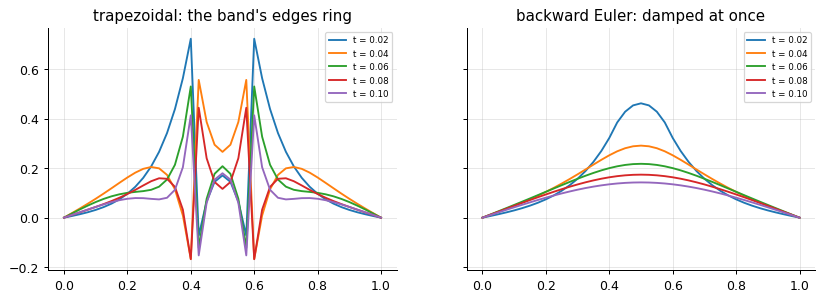

h lambda_max = -128: R = -0.969 for the trapezoidal rule, +0.0078 for backward Euler


In [5]:
u_rough = np.where((g.x > 0.4) & (g.x < 0.6), 1.0, 0.0)                     # a discontinuous initial state excites the fastest modes
h = 0.02
tz = ti.trapezoidal(f, u_rough, (0, 0.1), h, band=(1, 1), n_out=5)
be = ti.bdf(f, u_rough, (0, 0.1), h, 1, band=(1, 1), n_out=5)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for ax, s, title in ((axes[0], tz, "trapezoidal: the band's edges ring"), (axes[1], be, "backward Euler: damped at once")):
    for t, y in zip(s.t[1:], s.y[1:]):
        ax.plot(g.x, y, label=f"t = {t:.2f}")
    ax.set_title(title); ax.legend(fontsize=7)
plt.show()
print(f"h lambda_max = {h * lam[0].real:.0f}: R = {stiffness.stability_function('trapezoidal', h * lam[0].real).real:+.3f} for the trapezoidal rule, {stiffness.stability_function('backward_euler', h * lam[0].real).real:+.4f} for backward Euler")

With hλ_max ≈ −130, the trapezoidal rule's amplification factor for the sawtooth modes is −0.97: the edges of the
hot band flip sign every step and the solution oscillates for many steps although it is "stable". Backward
Euler's factor is 0.008 and the profile is smooth after one step. For rough data - and PDE initial data is
often rough - L-stability, not just A-stability, is required; BDF2 and Radau have it, the trapezoidal rule
(Crank-Nicolson) does not, which is why it is often started with a few backward-Euler steps.

## When do implicit methods win? A cost model

In [6]:
rows = []
for n in (20, 40, 80, 160, 320):
    g_ = grids.uniform(0, 1, n)
    lam_ = stiffness.spectrum(lambda t, u, g_=g_: op.diffusion(u, g_, 1.0, bc.Dirichlet(0.0), bc.Dirichlet(0.0), t), np.zeros(n + 1), band=(1, 1))
    lam_ = lam_[np.abs(lam_) > 1e-9]
    c = stiffness.cost_model(n + 1, lam_, 0.1, 1, explicit="rk4", implicit_h=0.1 / 100)
    rows.append((n, c["explicit_steps"], c["explicit_flops"], c["implicit_steps"], c["implicit_flops"], c["ratio"]))
print(pd.DataFrame(rows, columns=["n", "RK4 steps", "RK4 flops", "BDF steps", "BDF flops", "RK4/BDF"]).to_string(index=False, float_format="%.3g"))

  n  RK4 steps  RK4 flops  BDF steps  BDF flops  RK4/BDF
 20         58      14616        100   2.54e+04    0.575
 40        230     113160        100   4.96e+04     2.28
 80        919     893268        100    9.8e+04     9.11
160       3677    7103964        100   1.95e+05     36.5
320      14706   56647512        100   3.88e+05      146


Explicit work grows like n³ (steps ∝ n², work per step ∝ n); implicit work with a banded Jacobian grows like n
(a fixed number of steps for the accuracy, each a tridiagonal solve). The crossover is at a few dozen points;
by n = 320 the implicit method is over a hundred times cheaper, and the ratio keeps growing like n². In two dimensions, with the band of width n, the
implicit advantage is smaller but still decisive for diffusion-dominated problems; for problems whose
stiffness comes from advection or reaction alone, explicit methods remain competitive - the subject of the
later notebooks.

## Inside the algorithm: the stability limit from the stability polynomial

In [7]:
R = lambda z: 1 + z + z**2 / 2 + z**3 / 6 + z**4 / 24     # RK4
z = np.linspace(-3, 0, 30001)
print("RK4 stable down to z =", z[np.argmax(np.abs(R(z)) <= 1)], " -> h_max = 2.785/|lambda_min| =", 2.785 / abs(lam[0].real), "; library:", h_rk4)

RK4 stable down to z = -2.7852  -> h_max = 2.785/|lambda_min| = 0.00043582800633866107 ; library: 0.00043587394642984485


## Exercises
1. Repeat the integrator comparison for the advection equation `problems.advection_periodic(scheme='centred')` whose spectrum is imaginary. Which explicit methods are stable at all, and what does BDF2 do to the pulse's amplitude after one period?
2. Start Crank-Nicolson (the trapezoidal rule) on the hot band with two backward-Euler half steps (Rannacher's trick) and compare the ringing with the plain start.
3. **Implement it yourself:** write the trapezoidal rule for the linear semi-discrete heat equation with one factorisation of (I - hA/2) and reproduce the ringing figure; then halve h until the ringing disappears and relate that h to |R(h lambda_max)|.